### Домашнее задание Введение в статистику

Выполнила: Рытикова Кирена 

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

##### Задание 1 
Продукт считает, что среднее время на карточке вакансии равно 120 секунд. 
Дано: n=100 пользователей, выборочное среднее x̄=124 секунды, генеральное стандартное отклонение σ=25 секунд. Необходимо: сформулировать H₀, посчитать удаленность среднего от 120 в стандартных ошибках и решить, есть ли основание отвергать H₀.

Нулевая гипотеза: H₀: μ=120 секунд.
Альтренативная гипотеза: H₁: μ≠120.
Генеральное стандартное отклонение (σ) известно, используем z-test.

In [46]:
n = 100
x_mean = 124
mu_0 = 120
sigma = 25

se = sigma / np.sqrt(n)
z = (x_mean - mu_0) / se
p_value = 2*stats.norm.sf(abs(z))

print(f'стандартная ошибка SE = {se} секунды')
print(f'z = {z:.2f} стандартной ошибки')
print(f'p-value = {p_value:.2f}')

стандартная ошибка SE = 2.5 секунды
z = 1.60 стандартной ошибки
p-value = 0.11


Стандартная ошибка среднего равна 2.5 секунды, а среднее 124 секунды находится на 1.6 стандартной ошибки выше значения 120 секунд. Полученное p-value = 0.11 (больше 0.05). 
Оснований отвергнуть H₀ нет. Это не доказывает, что истинное среднее точно равно 120.

##### Задание 2 
Первая группа: n₁=40, x̄₁=50, s₁=10. Вторая: n₂=40, x̄₂=55, s₂=10. 
Найти разницу средних и 95%-й доверительный интервал, не предполагая равенство генеральных разбросов. Проверить, входит ли ноль в интервал, и какой самый маленький эффект, ещё согласующийся с данными (который не будет опровергать H₀).

In [47]:
n1, mean1, sd1 = 40, 50, 10
n2, mean2, sd2 = 40, 55, 10

difference = mean2 - mean1
se_diff = np.sqrt(sd1**2/n1 + sd2**2/n2)

df = (sd1**2/n1 + sd2**2/n2)**2 / ((sd1**2/n1)**2/(n1-1) + (sd2**2/n2)**2/(n2-1))

t_critical = stats.t.ppf(0.975, df)

ci_low = difference - t_critical*se_diff
ci_high = difference + t_critical*se_diff

print(f'Разница = {difference:.2f}')
print(f'95% CI=[{ci_low:.2f}, {ci_high:.2f}]')

Разница = 5.00
95% CI=[0.55, 9.45]


Эффект определен как 5 (разница второй и первой группы). 95%-й интервал примерно [0.55; 9.45], ноль не входит. Самый маленький положительный эффект, который ещё согласуется с данными: нижняя граница интервала (около 0.55).

##### Задание 3
Первая группа: 90 откликов на 1000 показов. Вторая: 120 на 1000. Каждый показ относится к своему пользователю, группы независимы. Сформулировать H₀ про две конверсии, найти разницу в процентных пунктах, статистику критерия двух долей и решение, отвергать ли H₀.

H₀: p₁=p₂. H₁: p₁≠p₂. 
Отклик - бинарный исход (отклик/нет отклика), пользователи независимы, значит используем z-критерий для двух пропорций.

In [48]:
responses1, shows1 = 90, 1000
responses2, shows2 = 120, 1000

p1 = responses1 / shows1
p2 = responses2 / shows2

pooled_p = (responses1 + responses2) / (shows1 + shows2)
se = np.sqrt(pooled_p*(1-pooled_p)*(1/shows1 + 1/shows2))
z = (p2-p1) / se
p_value = 2*stats.norm.sf(abs(z))

print(f'Конверсии: {p1:.1%} и {p2:.1%}')
print(f'Разница={(p2-p1)*100:.2f} п.п.')
print(f'z={z:.2f}')
print(f'p-value={p_value:.4f}')

Конверсии: 9.0% и 12.0%
Разница=3.00 п.п.
z=2.19
p-value=0.0287


Конверсии равны 9% и 12%, разница составляет 3 процентных пункта. z=2.19, p-value=0.029 < 0.05, поэтому есть основания отвергнуть H₀ о равенстве конверсий.

In [49]:
rng = np.random.default_rng(7)

##### Задание 4
2000 раз набрать две независимые группы по 200 наблюдений из одного N(0,1). Для каждой пары рассчитать t Уэлча и p-value. Нарисовать распределение p-value, описать его форму и объяснить ее.

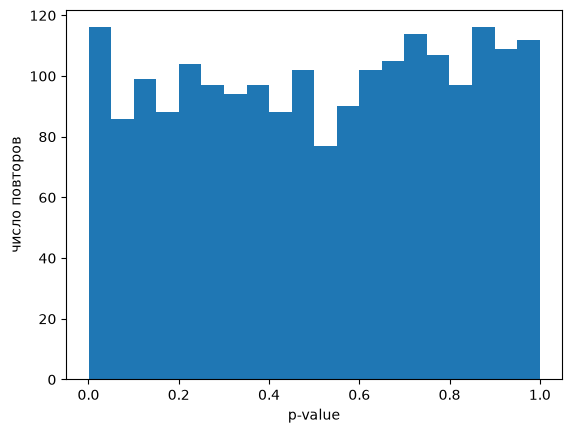

Доля p-value < 0.05: 0.057


In [50]:
p_values = []

for _ in range(2000):
    group1 = rng.normal(0, 1, size=200)
    group2 = rng.normal(0, 1, size=200)
    
    result = stats.ttest_ind(group1, group2, equal_var=False)
    p_values.append(result.pvalue)

plt.hist(p_values, bins=20)
plt.xlabel('p-value') 
plt.ylabel('число повторов')
plt.show()

print('Доля p-value < 0.05:', np.mean(np.array(p_values) < 0.05))

Гистрограмма выглядит приблизительно равномерной на отрезке [0,1]. Доля p-value ниже 0.05 составила 5.7%, что около 114 проверок из 2000. Так как обе группы сгенерированы из одного распределения, нулевая гипотеза верна.

##### Задание 5
1000 раз сгенерировать первую группу из N(0,1), n=60; вторую из N(1,1), n=60, затем заменить два её наблюдения на −50. Рассчитать разницу средних, t Уэлча, U Манна–Уитни и p-value обоих критериев. Построить распределения статистик и p-value, отметить 0.05, сравнить решения и объяснить возможное расхождение.

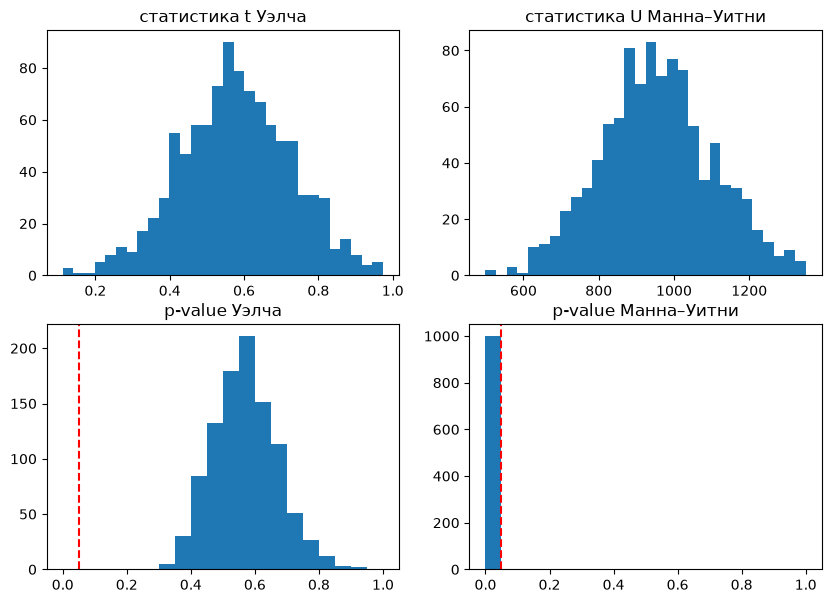

Средняя разница средних: 0.6969427827488955
Доля p<0.05 (Уэлч): 0.0
Доля p<0.05 (Манн–Уитни): 1.0


In [51]:
welch_t = []
welch_p = []
mw_u = []
mw_p =[]
mean_diffs = []

for i in range(1000):
    group1 = rng.normal(0, 1, size=60)
    group2 = rng.normal(1, 1, size=60)
    group2[:2] = -50

    mean_diffs.append(group1.mean() - group2.mean())

    welch_result = stats.ttest_ind(group1, group2, equal_var=False, alternative="two-sided")
    welch_t.append(welch_result.statistic)
    welch_p.append(welch_result.pvalue)

    mw_result = stats.mannwhitneyu(group1, group2, alternative='two-sided')
    mw_u.append(mw_result.statistic)
    mw_p.append(mw_result.pvalue)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(welch_t, bins=30)
axes[0, 0].set_title("статистика t Уэлча")

axes[0, 1].hist(mw_u, bins=30)
axes[0, 1].set_title("статистика U Манна–Уитни")

axes[1, 0].hist(welch_p, bins=20, range=(0, 1))
axes[1, 0].axvline(0.05, color="red", linestyle="--")
axes[1, 0].set_title("p-value Уэлча")

axes[1, 1].hist(mw_p, bins=20, range=(0, 1))
axes[1, 1].axvline(0.05, color="red", linestyle="--")
axes[1, 1].set_title("p-value Манна–Уитни")

plt.show()

print('Средняя разница средних:', np.mean(mean_diffs))
print('Доля p<0.05 (Уэлч):', np.mean(np.array(welch_p)<.05))
print('Доля p<0.05 (Манн–Уитни):', np.mean(np.array(mw_p)<.05))

Средняя разница составила около 0.686 (рассчитана как первая группа - вторая). p-value критерия Уэлча оказались выше 0.05: он не отверг нулевую гипотезу о равенстве средних ни в одном из 1000 повторов. p-value Манна–Уитни сосредоточены около нуля: критерий отверг нулевую гипотезу во всех повторах. Результаты критериев разошлись, потому что Уэлч сравнивает средние и чувствителен к выбросам, а Манна–Уитни работает с рангами и не проверяет разницу средних.

##### Задание 6.
Один раз сгенерировать первую группу из N(10,2), n₁=80, вторую из N(10.8,2.6), n₂=75. Найти 95%-й интервал Уэлча для разницы «вторая минус первая» и p-value критерия Уэлча. Решить, отвергается ли H₀ при двустороннем пороге 5%, и указать, входит ли 0 в интервал и какой самый маленький эффект ещё согласуется с данными.

In [52]:
rng = np.random.default_rng(7)

group1 = rng.normal(10, 2, size=80)
group2 = rng.normal(10.8, 2.6, size=75)

result6 = stats.ttest_ind(group2, group1, equal_var=False)
ci6 = result6.confidence_interval(confidence_level=0.95)
difference6 = group2.mean() - group1.mean()

print(f'Средние: {group1.mean():.2f}, {group2.mean():.2f}')
print(f'Разница = {difference6:.2f}')
print(f'95% CI=[{ci6.low:.2f}, {ci6.high:.2f}]')
print(f'p-value={result6.pvalue:.3f}')

Средние: 9.65, 10.40
Разница = 0.76
95% CI=[0.11, 1.40]
p-value=0.022


В полученных выборках среднее второй группы выше среднего первой примерно на 0.757. 95% доверительный интвал Уэлча: [0.109, 1.404]. p-value критерия Уэлча примерно равно 0.0225. Так как p-value меньше 0.05, то нулевую гипотезу отвергаем. Ноль в ДИ не попадает. Наименьшая положительная разница, ещё согласующаяся с данными на уровне 95% - это нижняя граница интервала, примерно 0.109.

##### Задание 7.
Взять те же две группы, что в предыдущей задаче, и 2000 раз заново собрать выборки того же размера: каждый раз берем наблюдения из уже полученных групп с возвращением и заново считаем разницу средних. 
Нарисовать распределение этих разниц.
Интервал строим по центральным 95% бутстрап-разниц и сравниваем с интервалом Уэлча. Посчитать, в какой доле таких повторных выборок разница получилась не больше нуля. Объяснить, можно ли эту долю назвать p-value.

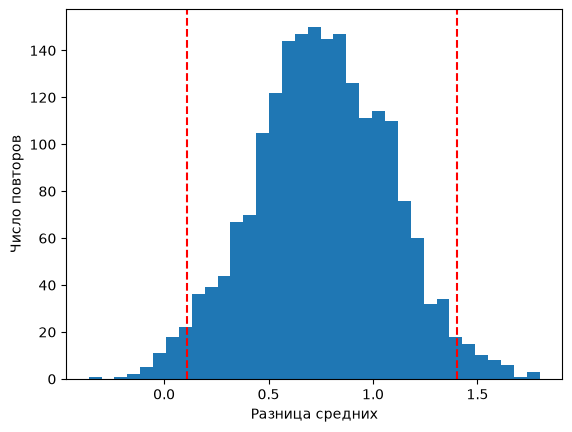

Разница в исходных группах: 0.76
95% интервал Уэлча: [0.109, 1.404]
95% бутстрап-интервал: [0.111, 1.403]
Доля бутстрап-разниц не больше 0: 0.9%


In [53]:
bootstrap_diffs = []

for _ in range(2000):
    sample1 = rng.choice(group1, size=len(group1), replace=True)
    sample2 = rng.choice(group2, size=len(group2), replace=True)
    difference = sample2.mean() - sample1.mean()
    bootstrap_diffs.append(difference)

bootstrap_diffs = np.array(bootstrap_diffs)

ci_bootstrap = np.quantile(bootstrap_diffs, [0.025, 0.975])

fraction_zero = np.mean(bootstrap_diffs <= 0)

plt.hist(bootstrap_diffs, bins=35)
plt.axvline(ci_bootstrap[0], color="red", linestyle="--")
plt.axvline(ci_bootstrap[1], color="red", linestyle="--")
plt.xlabel("Разница средних")
plt.ylabel("Число повторов")
plt.show()

print(f"Разница в исходных группах: {group2.mean() - group1.mean():.2f}")
print(f"95% интервал Уэлча: [{ci6.low:.3f}, {ci6.high:.3f}]")
print(f"95% бутстрап-интервал: [{ci_bootstrap[0]:.3f}, {ci_bootstrap[1]:.3f}]")
print(f"Доля бутстрап-разниц не больше 0: {fraction_zero:.1%}")


Бутстрап-интервал получен повторным набором с возвращением из групп задачи 6. Он близок к интервалу Уэлча и оба интервала не содержат нуля. В бутстрап-повторах доля разниц, не превышающих ноль, составила около 0.9%. Эту долю нельзя называть p-value, так как бутстрап здесь оценивает неопределенность разницы средних по наблюдавшимся группам. p-value отвечает на вопрос: насколько необычны наблюдаемые данные (или ещё более экстремальные) при условии, что нулевая гипотеза верна.